# Fourier diffusion: reproduce the full example

I calculate diffusion of two cosine modes on a periodic line. c is a dimensionless concentration field, x is position on a dimensionless line of length 2π, t is dimensionless time, and D=1 is the dimensionless diffusivity. The mode with wave number 4 decays sixteen times faster than the mode with wave number 1.

I develop this calculation in small steps. I run a cell, inspect its result and test it before adding the next part. Run the cells in order in Jupyter. A code cell defines a part of the calculation or carries it out; defining a function does not run it.

I permit free noncommercial teaching, learning and demonstrations with acknowledgment. Research and commercial use require my written permission. Earlier licensed releases retain their permissions. [Read the code-use terms](https://saswataiith.github.io/using-my-resources/).

Copyright (c) 2026 Saswata Bhattacharyya.

## 1. Prepare the Python environment

I install the packages listed in the next cell once in the same environment as the notebook. In Jupyter or Colab, remove the comment marker from the installation line below if a package is missing. NumPy stores arrays and evaluates numerical operations. Matplotlib displays plots. Pillow reads and writes images. This installation does not change the model parameters.

In [1]:
# %pip install numpy matplotlib
import numpy as np
assert np.isfinite(np.array([0.0, 1.0])).all()
print("NumPy is ready:", np.__version__)

NumPy is ready: 2.1.3


## 2. Choose the input values

I retain the default values from the original calculation. The output name locates the files written by this notebook.

In [2]:
output = 'diffusion-results'

## 3. Prepare the next part of the calculation

I define the following operations. These are the same operations as in the original source, written on separate lines so their order is clear. Inspect their values before running the next cell.

In [3]:
import sys
from pathlib import Path
import numpy as np

## 4. Set up the Fourier grid

I calculate wave numbers consistent with the grid spacing and periodic domain. k2 denotes the squared magnitude of a wave vector. The denominator contains the term treated implicitly in the original update. The zero Fourier mode represents the spatial mean.

In [4]:
out = Path(output)
out.mkdir(parents=True, exist_ok=True)
n = 128
x = 2 * np.pi * np.arange(n) / n
k = 2 * np.pi * np.fft.fftfreq(n, d=2 * np.pi / n)
c0 = 1 + 0.4 * np.cos(x) + 0.2 * np.cos(4 * x)
rows = []

## 5. Repeat the operation and inspect each case

I repeat the operation over the specified cases. Read the loop variable first, then follow what changes on each pass. The assertions check the stated numerical or topological condition.

In [5]:
for t in [0, 0.02, 0.1, 0.3, 1.0]:
    c = np.fft.ifft(np.fft.fft(c0) * np.exp(-k * k * t)).real
    exact = 1 + 0.4 * np.exp(-t) * np.cos(x) + 0.2 * np.exp(-16 * t) * np.cos(4 * x)
    rows.append([t, c.mean(), np.max(np.abs(c - exact))])
    np.savetxt(out / f'profile_{t:.2f}.csv', np.column_stack([x, c]), delimiter=',')

## 6. Check the result before continuing

I check finite values, conservation or the known reference result as specified below. An assertion stops the notebook if the condition fails. Inspect the quantities and tolerance rather than suppressing a failure.

In [6]:
np.savetxt(out / 'diagnostics.csv', rows, delimiter=',', header='time,mean,max_exact_error', comments='')
assert max((r[2] for r in rows)) < 1e-12
print('Fourier diffusion: max exact error', max((r[2] for r in rows)))

Fourier diffusion: max exact error 4.440892098500626e-16


## Plot and interpret the result

I compare the profiles at the saved times. The rapidly varying mode fades first, while the mean remains 1. The horizontal coordinate and concentration are dimensionless.

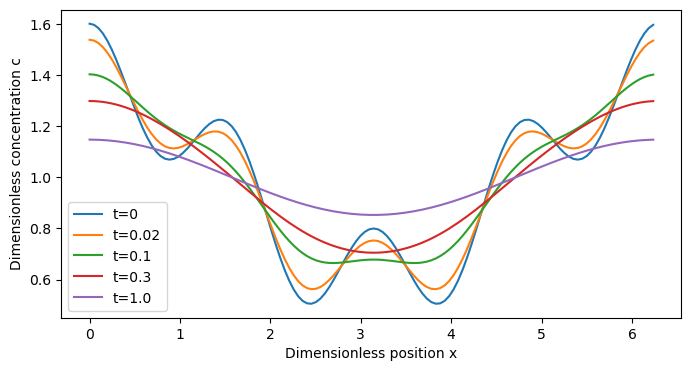

In [7]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8, 4))
for t in (0, .02, .1, .3, 1.):
    profile = np.loadtxt(out / f"profile_{t:.2f}.csv", delimiter=",")
    ax.plot(profile[:, 0], profile[:, 1], label=f"t={t}")
ax.set_xlabel("Dimensionless position x")
ax.set_ylabel("Dimensionless concentration c")
ax.legend()
plt.show()

## 7. Review and extend the calculation

I first restart the kernel and run all the required cells. Then I change one input, predict its effect and compare the result with that prediction. A successful check establishes the tested property; it does not establish convergence or equilibrium. I retain the [complete script](https://saswataiith.github.io/files/mesoscale/examples/diffusion.py) for command-line use. The notebook embeds the calculation directly and does not need that script to run.